# Титаник өгөгдлийн шинжилгээ — Алхам алхамын Notebook

`lab/titanic_analysis_script.py` файлаас **код өөрчлөлгүй** (мөр бүр яг адилхан) cell-д хуваарилсан хувилбар.

**Урсгал:** Ачаалах → Ажиглах → Цэвэрлэх → Дүрслэх → Хамаарал → Кодлох → Хуваах → Сургах → Үнэлэх → Дүгнэх


## Шаардлагатай сангууд

In [1]:
"""
Титаник өгөгдлийн шинжилгээ - Алхам алхамын гарын авлага
Өгөгдлийн ухааны оюутнуудад зориулсан практик жишээ
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = ['DejaVu Sans', 'Arial Unicode MS']
plt.rcParams['figure.figsize'] = (10, 6)

print("ТИТАНИК ӨГӨГДЛИЙН ШИНЖИЛГЭЭ - ПРАКТИК ЖИШЭЭ")
print("=" * 60)

ТИТАНИК ӨГӨГДЛИЙН ШИНЖИЛГЭЭ - ПРАКТИК ЖИШЭЭ


## АЛХАМ 1: Өгөгдөл ачаалах

In [2]:
print("\nАЛХАМ 1: Өгөгдөл ачаалах")
print("-" * 30)

TITANIC_URL = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'

try:
    df = pd.read_csv('titanic.csv')
    print("Өгөгдөл локал titanic.csv файлаас ачаалагдлаа")
except FileNotFoundError:
    try:
        df = pd.read_csv(TITANIC_URL)
        df.to_csv('titanic.csv', index=False)
        print(f"Өгөгдөл татаж авлаа -> lab/titanic.csv (дахин ачаалахад хурдан)")
    except Exception as url_error:
        print(f"URL-аас ч татаж чадсангүй ({url_error}).")
        print("https://www.kaggle.com/c/titanic/data")
        np.random.seed(42)
        df = pd.DataFrame({
            'PassengerId': range(1, 101),
            'Survived': np.random.choice([0, 1], 100, p=[0.6, 0.4]),
            'Pclass': np.random.choice([1, 2, 3], 100, p=[0.2, 0.3, 0.5]),
            'Sex': np.random.choice(['male', 'female'], 100, p=[0.65, 0.35]),
            'Age': np.random.normal(30, 15, 100),
            'SibSp': np.random.poisson(0.5, 100),
            'Parch': np.random.poisson(0.3, 100),
            'Fare': np.random.lognormal(3, 1, 100),
            'Embarked': np.random.choice(['S', 'C', 'Q'], 100, p=[0.7, 0.2, 0.1])
        })
        print("Жишээ өгөгдөл үүсгэлээ")

print(f"Өгөгдлийн хэмжээ: {df.shape}")
print(f"Багануудын нэр: {list(df.columns)}")


АЛХАМ 1: Өгөгдөл ачаалах
------------------------------
Өгөгдөл локал titanic.csv файлаас ачаалагдлаа
Өгөгдлийн хэмжээ: (891, 12)
Багануудын нэр: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


## АЛХАМ 2: Анхдагч судалгаа

In [3]:
print("\nАЛХАМ 2: Анхдагч судалгаа")
print("-" * 30)

print("Өгөгдлийн ерөнхий мэдээлэл:")
print(df.info())

print("\nСтатистик үзүүлэлтүүд:")
print(df.describe())

print("\nХоосон утгууд:")
missing_data = df.isnull().sum()
print(missing_data[missing_data > 0])


АЛХАМ 2: Анхдагч судалгаа
------------------------------
Өгөгдлийн ерөнхий мэдээлэл:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

Статистик үзүүлэлтүүд:
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891

## АЛХАМ 3: Өгөгдөл цэвэрлэгээ

**АЛХАМ 3-ын 3 логик дүүргэлт:**
1. **Цол (Title)** → `Name`-ээс `Mr/Mrs/Miss/Master` салгаж, ховор цолыг `Rare` болгон нэгтгэнэ.
   `Age`-г **нийт медиан (28) биш, цолны медианаар** нөхнө (`Master` ≈ 3.5 нас!).
2. **Suulsын боомт (Embarked)** → `Pclass=1` + `Fare>=70` (≈80$) бол `C` (Cherbourg); үлдсэнийг нийт mode-оор.
3. **Cabin → Deck** → 77% хоосон тул устгахын оронд эхний үсгийг (`A,B,C…`, `U`=Unknown) шинж болгоно.


In [4]:
print("\nАЛХАМ 3: Өгөгдөл цэвэрлэгээ")
print("-" * 30)

if 'Name' in df.columns:
    df['Title'] = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
    rare_titles = ['Dr', 'Rev', 'Dona', 'Jonkheer', 'Countess', 'Lady', 'Sir',
                   'Col', 'Major', 'Don', 'Mme', 'Mlle', 'Ms', 'Capt']
    df['Title'] = df['Title'].replace(rare_titles, 'Rare')
    print("\nЦол бүрийн дундаж нас (медиан):")
    print(df.groupby('Title')['Age'].median().round(1))

if 'Age' in df.columns and df['Age'].isnull().any():
    df['Age_was_missing'] = df['Age'].isnull().astype(int)
    n_missing_age = int(df['Age_was_missing'].sum())
    df['Age'] = df.groupby('Title')['Age'].transform(lambda x: x.fillna(x.median()))
    df['Age'] = df.groupby(['Sex', 'Pclass'])['Age'].transform(lambda x: x.fillna(x.median()))
    df['Age'] = df['Age'].fillna(df['Age'].median())
    print(f"Age: {n_missing_age} хоосон утгыг цол/бүлгээр нөхлөө "
          f"(Age_was_missing шинж нэмэгдлээ)")

if 'Embarked' in df.columns and df['Embarked'].isnull().any():
    print("\n1-р ангийнхны буудлаар тасалбарын үнийн медиан:")
    print(df[df['Pclass'] == 1].groupby('Embarked')['Fare'].median().round(1))
    cond = df['Embarked'].isnull() & (df['Pclass'] == 1) & (df['Fare'] >= 70)
    df.loc[cond, 'Embarked'] = 'C'
    df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
    print("Embarked багананы хоосон утгыг Анги/Үнээр нөхлөө")

if 'Cabin' in df.columns:
    df['Deck'] = df['Cabin'].fillna('U').str[0]
    df.drop('Cabin', axis=1, inplace=True)
    print("Cabin -> Deck шинж үүсгэлээ (U = Unknown):")
    print(df['Deck'].value_counts())

columns_to_drop = ['Name', 'Ticket']
existing_columns = [col for col in columns_to_drop if col in df.columns]
if existing_columns:
    df.drop(existing_columns, axis=1, inplace=True)
    print(f"{existing_columns} багануудыг устгав")

print("\nДүүргэлтийн дараах хоосон утга:")
missing_after = df.isnull().sum()
if missing_after.sum() == 0:
    print("   Хоосон утга үлдээгүй")
else:
    print(missing_after[missing_after > 0])

print("Цэвэрлэгээний дараах өгөгдлийн хэмжээ:", df.shape)
print("Шинээр үүссэн шинжүүд:",
      [c for c in ['Title', 'Deck', 'Age_was_missing'] if c in df.columns])


АЛХАМ 3: Өгөгдөл цэвэрлэгээ
------------------------------

Цол бүрийн дундаж нас (медиан):
Title
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Rare      44.5
Name: Age, dtype: float64
Age: 177 хоосон утгыг цол/бүлгээр нөхлөө (Age_was_missing шинж нэмэгдлээ)

1-р ангийнхны буудлаар тасалбарын үнийн медиан:
Embarked
C    78.3
Q    90.0
S    52.0
Name: Fare, dtype: float64
Embarked багананы хоосон утгыг Анги/Үнээр нөхлөө
Cabin -> Deck шинж үүсгэлээ (U = Unknown):
Deck
U    687
C     59
B     47
D     33
E     32
A     15
F     13
G      4
T      1
Name: count, dtype: int64
['Name', 'Ticket'] багануудыг устгав

Дүүргэлтийн дараах хоосон утга:
   Хоосон утга үлдээгүй
Цэвэрлэгээний дараах өгөгдлийн хэмжээ: (891, 12)
Шинээр үүссэн шинжүүд: ['Title', 'Deck', 'Age_was_missing']


## АЛХАМ 4: Амьд үлдэх ерөнхий статистик

In [5]:
print("\nАЛХАМ 4: Амьд үлдэх ерөнхий статистик")
print("-" * 30)

if 'Survived' in df.columns:
    survival_rate = df['Survived'].mean()
    print(f"Ерөнхий амьд үлдэх хувь: {survival_rate:.1%}")
    print(f"Нийт хүн: {len(df)}")
    print(f"Амьд үлдсэн: {df['Survived'].sum()}")
    print(f"Нас барсан: {len(df) - df['Survived'].sum()}")
else:
    print("'Survived' багана олдсонгүй")


АЛХАМ 4: Амьд үлдэх ерөнхий статистик
------------------------------
Ерөнхий амьд үлдэх хувь: 38.4%
Нийт хүн: 891
Амьд үлдсэн: 342
Нас барсан: 549


## АЛХАМ 5: Ангиар шинжилгээ


АЛХАМ 5: Ангиар шинжилгээ
------------------------------
Ангиар ангилсан амьд үлдэх харьцаа:
        Нийт  Амьд үлдсэн  Хувь
Pclass                         
1        216          136  63.0
2        184           87  47.3
3        491          119  24.2


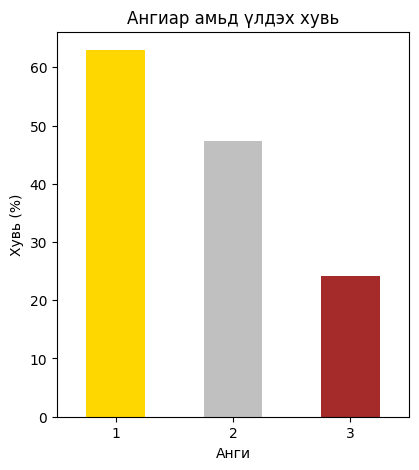

In [6]:
print("\nАЛХАМ 5: Ангиар шинжилгээ")
print("-" * 30)

if 'Pclass' in df.columns and 'Survived' in df.columns:
    class_survival = df.groupby('Pclass')['Survived'].agg(['count', 'sum', 'mean'])
    class_survival.columns = ['Нийт', 'Амьд үлдсэн', 'Хувь']
    class_survival['Хувь'] = class_survival['Хувь'] * 100
    print("Ангиар ангилсан амьд үлдэх харьцаа:")
    print(class_survival.round(1))
    
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    class_survival['Хувь'].plot(kind='bar', color=['gold', 'silver', 'brown'])
    plt.title('Ангиар амьд үлдэх хувь')
    plt.xlabel('Анги')
    plt.ylabel('Хувь (%)')
    plt.xticks(rotation=0)

### Олдвор 2: Нийгмийн анги чухал нөлөө үзүүлсэн
(1-р анги 63%, 3-р анги 24% амьд үлдсэн)

**1. Хэрхэн олох вэ? (Техник тал)**

- **Загалмайлсан хүснэгт (Cross-tabulation):** Зорчигчдын ангилал буюу `Pclass` (1, 2, 3) баганыг `Survived` баганатай огтлолцуулж харна.
- **График дүрслэл:** Зэрэгцээ баганан график (Bar chart) зурж харахад 1-р ангийн амьд үлдэх багана хамгийн өндөр, харин 3-р ангийнх нас барсан багана хамгийн өндөр байгаа нь нүдэнд шууд буудаг.
- **Хүйс ба Ангийн давхарлал:** "1-р ангийн эрэгтэй" vs "3-р ангийн эмэгтэй" гэх мэтээр гүнзгийрүүлж харахад 1-р ангид байсан ч эрэгтэй хүн бол амьд үлдэх магадлал бага байсныг олж хардаг.

**2. Логик чанар, шалтгаан (Бодит амьдрал)**

- **Хөлөг онгоцны бүтэц:** 1-р ангийн кабин, өрөөнүүд хөлөг онгоцны хамгийн дээд давхруудад буюу аврах завьтай хамгийн ойр байрлаж байсан. Харин 3-р ангийн өрөөнүүд хөлгийн хамгийн доод давхарт, хэцүү төөрдөг байгууламж дотор байв.
- **Мэдээллийн хүртээмж:** 1-р ангийн зорчигчдод үйлчилдэг тусгай үйлчлэгч нар тэднийг сэрээж, аврах хантаазыг нь өмсүүлэн дээш дагуулж гарсан бол 3-р ангийнханд нэгдсэн байдлаар мэдээлэл маш оройтож очсон.
- **Хаалт ба түгжээ:** Доод давхраас дээшээ гарах хаалгануудыг усанд автахаас сэргийлж, мөн сандралдсан хүмүүсийг бөөгнөрүүлэхгүй гэж багийнхан түгжсэн байсан нь 3-р ангийнхан олноор амиа алдах шалтгаан болсон.


## АЛХАМ 6: Хүйсээр шинжилгээ


АЛХАМ 6: Хүйсээр шинжилгээ
------------------------------
Хүйсээр ангилсан амьд үлдэх харьцаа:
         Нийт  Амьд үлдсэн  Хувь
Эмэгтэй   314          233  74.2
Эрэгтэй   577          109  18.9


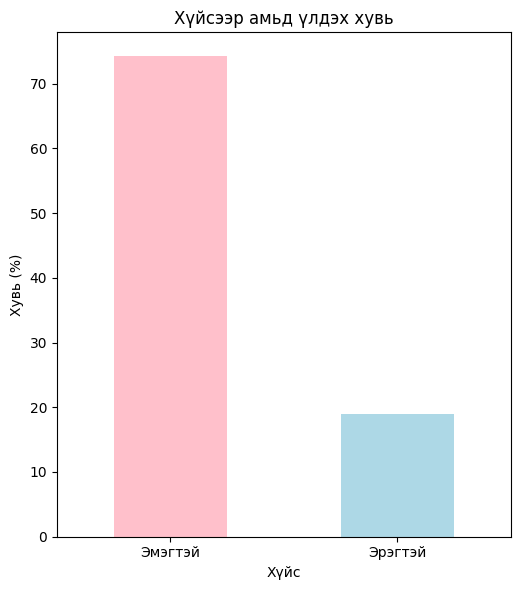

In [7]:
print("\nАЛХАМ 6: Хүйсээр шинжилгээ")
print("-" * 30)

if 'Sex' in df.columns and 'Survived' in df.columns:
    gender_survival = df.groupby('Sex')['Survived'].agg(['count', 'sum', 'mean'])
    gender_survival.columns = ['Нийт', 'Амьд үлдсэн', 'Хувь']
    gender_survival['Хувь'] = gender_survival['Хувь'] * 100
    gender_survival.index = ['Эмэгтэй', 'Эрэгтэй']
    print("Хүйсээр ангилсан амьд үлдэх харьцаа:")
    print(gender_survival.round(1))
    
    plt.subplot(1, 2, 2)
    gender_survival['Хувь'].plot(kind='bar', color=['pink', 'lightblue'])
    plt.title('Хүйсээр амьд үлдэх хувь')
    plt.xlabel('Хүйс')
    plt.ylabel('Хувь (%)')
    plt.xticks(rotation=0)
    
    plt.tight_layout()
    plt.show()

## АЛХАМ 7: Насны шинжилгээ


АЛХАМ 7: Насны шинжилгээ
------------------------------
Насны бүлгээр амьд үлдэх харьцаа:
          Тоо  Амьд үлдэх хувь
AgeGroup                      
0-10       68             58.8
11-20     115             38.3
21-30     385             31.2
31-40     172             48.3
41-50      87             37.9
51-60      42             40.5
60+        22             22.7


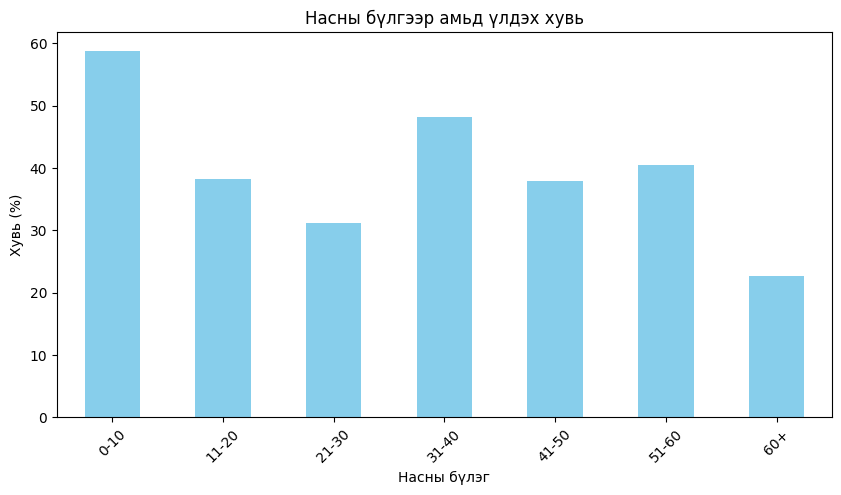

In [8]:
print("\nАЛХАМ 7: Насны шинжилгээ")
print("-" * 30)

if 'Age' in df.columns and 'Survived' in df.columns:
    df['AgeGroup'] = pd.cut(df['Age'], 
                           bins=[0, 10, 20, 30, 40, 50, 60, 100],
                           labels=['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '60+'])
    
    age_survival = df.groupby('AgeGroup')['Survived'].agg(['count', 'mean'])
    age_survival.columns = ['Тоо', 'Амьд үлдэх хувь']
    age_survival['Амьд үлдэх хувь'] = age_survival['Амьд үлдэх хувь'] * 100
    print("Насны бүлгээр амьд үлдэх харьцаа:")
    print(age_survival.round(1))
    
    plt.figure(figsize=(10, 5))
    age_survival['Амьд үлдэх хувь'].plot(kind='bar', color='skyblue')
    plt.title('Насны бүлгээр амьд үлдэх хувь')
    plt.xlabel('Насны бүлэг')
    plt.ylabel('Хувь (%)')
    plt.xticks(rotation=45)
    plt.show()

### Олдвор 1: "Эмэгтэй, хүүхэд эхлээд" зарчим бодитоор хэрэгжсэн
(Эмэгтэйчүүд 74%, эрэгтэйчүүд 19% орчим амьд үлдсэн)

**1. Хэрхэн олох вэ? (Техник тал)**

- **Бүлэглэх (Grouping):** Өгөгдлийг `Sex` (Хүйс) баганаар нь 2 хуваагаад, бүлэг тус бүр дэх `Survived` (Амьд үлдсэн хувь)-ийг бодож гаргадаг.
- **Насны шүүлт (Filtering):** `Age` баганыг ашиглан 16 ба түүнээс доош насныхныг "Хүүхэд" гэж ялгаад, тэдний амьд үлдэх хувийг насанд хүрэгчидтэй харьцуулж үздэг.
- **Хүйс ба Насыг давхарлах:** жишээ нь: насанд хүрсэн эрэгтэй хүн vs эрэгтэй хүүхэд — энээр нас биед хүрсэн эрчүүд хамгийн сүүлд үлдсэн гэдгийг тоогоор баталдаг.

**2. Логик чанар, шалтгаан (Бодит амьдрал)**

- **Нийгмийн хэм хэмжээ:** 1912 оны үед (Эдвардын эрин үе) эр зориг, эмэгтэйчүүдээ хүндлэх ёс суртахуун нийгэмд маш хүчтэй байсан.
- **Ахмадын тушаал:** Титаникийн ахмад Эдвард Смит "Эмэгтэйчүүд, хүүхдүүдийг эхлээд аврах завинд суулга" гэсэн хатуу тушаал өгсөн. Зарим усан цэргүүд үүнийг "Зөвхөн эмэгтэй, хүүхдүүд" гэж ойлгоод, завь дүүрээгүй байсан ч эрчүүдийг суулгахгүй буцааж байжээ.


## АЛХАМ 8: Тасалбарын үнийн шинжилгээ

In [9]:
print("\nАЛХАМ 8: Тийм сүүлийн үнийн шинжилгээ")
print("-" * 30)

if 'Fare' in df.columns and 'Survived' in df.columns:
    df['FareGroup'] = pd.cut(df['Fare'], 
                            bins=[0, 10, 50, 100, df['Fare'].max() + 1],
                            labels=['0-10', '10-50', '50-100', '100+'])
    
    fare_survival = df.groupby('FareGroup')['Survived'].agg(['count', 'mean'])
    fare_survival.columns = ['Тоо', 'Амьд үлдэх хувь']
    fare_survival['Амьд үлдэх хувь'] = fare_survival['Амьд үлдэх хувь'] * 100
    print("Тийм сүүлийн үнээр амьд үлдэх харьцаа:")
    print(fare_survival.round(1))


АЛХАМ 8: Тийм сүүлийн үнийн шинжилгээ
------------------------------
Тийм сүүлийн үнээр амьд үлдэх харьцаа:
           Тоо  Амьд үлдэх хувь
FareGroup                      
0-10       321             20.6
10-50      395             42.0
50-100     107             65.4
100+        53             73.6


## АЛХАМ 9: Корреляцийн шинжилгээ


АЛХАМ 9: Корреляцийн шинжилгээ
------------------------------
Корреляцийн матриц:
                 PassengerId  Survived  Pclass    Age  SibSp  Parch   Fare  \
PassengerId            1.000    -0.005  -0.035  0.043 -0.058 -0.002  0.013   
Survived              -0.005     1.000  -0.338 -0.079 -0.035  0.082  0.257   
Pclass                -0.035    -0.338   1.000 -0.354  0.083  0.018 -0.549   
Age                    0.043    -0.079  -0.354  1.000 -0.266 -0.188  0.098   
SibSp                 -0.058    -0.035   0.083 -0.266  1.000  0.415  0.160   
Parch                 -0.002     0.082   0.018 -0.188  0.415  1.000  0.216   
Fare                   0.013     0.257  -0.549  0.098  0.160  0.216  1.000   
Age_was_missing       -0.020    -0.092   0.173 -0.047  0.019 -0.124 -0.101   

                 Age_was_missing  
PassengerId               -0.020  
Survived                  -0.092  
Pclass                     0.173  
Age                       -0.047  
SibSp                      0.019  
Parc

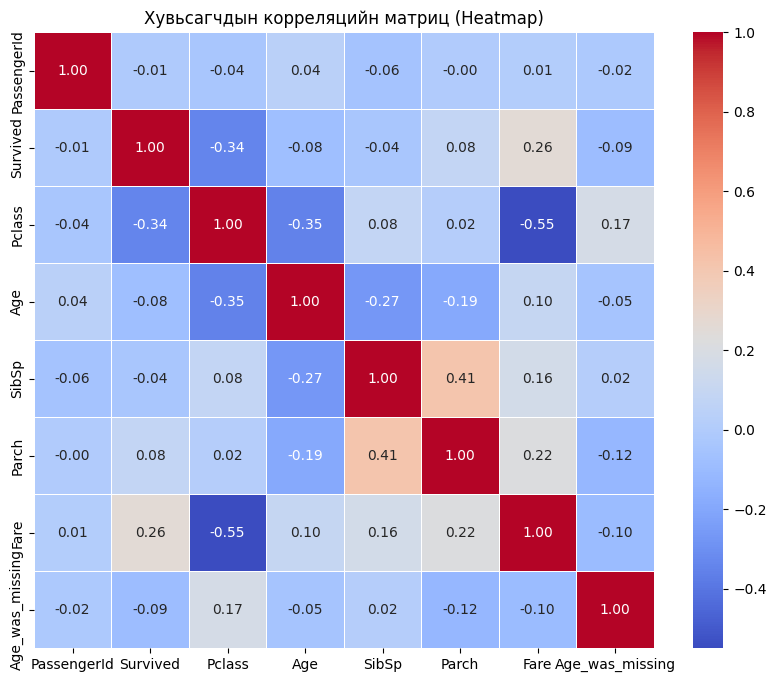

In [10]:
print("\nАЛХАМ 9: Корреляцийн шинжилгээ")
print("-" * 30)

numeric_cols = df.select_dtypes(include=[np.number]).columns
if len(numeric_cols) > 1:
    correlation_matrix = df[numeric_cols].corr()
    print("Корреляцийн матриц:")
    print(correlation_matrix.round(3))
    
    if 'Survived' in correlation_matrix.columns:
        print(f"\nАмьд үлдэхтэй хамгийн их хамааралтай:")
        survived_corr = correlation_matrix['Survived'].abs().sort_values(ascending=False)
        for col, corr in survived_corr.items():
            if col != 'Survived':
                print(f"   {col}: {corr:.3f}")

if 'correlation_matrix' in globals():
    plt.figure(figsize=(10, 8))
    sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm",
                fmt=".2f", linewidths=0.5)
    plt.title("Хувьсагчдын корреляцийн матриц (Heatmap)")
    plt.show()

### Хэрхэн унших вэ: Корреляцийн heatmap

Улаан = эерэг, цэнхэр = сөрөг хамаарал.

- **Pclass (-0.34)** — хамгийн хүчтэй сөрөг: анги тоо өсөх тусам (1-ээс 3) амьд үлдэх магадлал буурна.
- **Fare (+0.26)** — тасалбарын үнэ өндөр = амьд үлдэх өндөр (Олдвор 3).
- **Sex → one-hot** — эмэгтэй гэдэг эерэг тул хүйсийн нөлөө хамгийн хүчтэй (Олдвор 1).


### Олдвор 3: Эдийн засгийн байдал амьд үлдэхтэй шууд холбоотой

**1. Хэрхэн олох вэ? (Техник тал)**

- **Корреляци (Хамаарал):** `Fare` (Тасалбарын үнэ) багана болон `Survived` баганын хоорондын математик хамаарлыг (Correlation) бодож гаргадаг. Хамаарал нь эерэг (үнэ өсөх тусам амьд үлдэх магадлал дагаж өссөн) гардаг.
- **Бүлэгт хуваах (Binning):** Тасалбарын үнийг 0-20$, 20-50$, 50-100$, 100$+ гэх мэтээр бүлэглээд, бүлэг тус бүрийн амьд үлдсэн хувийг харьцуулна. Баян зорчигчдын бүлэг дэх хувь хамаагүй өндөр гарна.

**2. Логик чанар, шалтгаан (Бодит амьдрал)**

- **Хөрөнгө мөнгө = Давуу эрх:** Энэ нь "Нийгмийн анги"-тай маш төстэй боловч илүү нарийвчилсан утга юм. Нэг ангилалд (жишээ нь 1-р анги) байсан ч хамгийн өндөр үнэтэй тасалбар (Premium suite) авсан хүмүүс хамгийн түрүүнд, хамгийн тухтай завинд суух боломжтой байсан.
- **Хэл ам нэвтрэх:** 3-р ангид буюу хамгийн хямд тасалбараар зорчиж байсан хүмүүсийн ихэнх нь Англи хэл мэддэггүй гадаадын цагаачид байв. Тиймээс багийнхны өгсөн заавар, анхааруулгыг ойлгохгүй байх асуудал гарсан.


## Гүнзгий (Multivariate) шинжилгээ — 3 ухаалаг график

Титаникийн өгөгдөл дээр анализ хийх хамгийн ухаалаг бөгөөд мэргэжлийн арга бол хувьсагчдыг нэг нэгээр нь салгаж харах биш, харин 3-4 хувьсагчийг нэгэн зэрэг давхарлаж харах (Multivariate Analysis) юм. Энэ нь бидэнд энгийн нүдээр харагдахгүй гүнзгий логик зүй тогтлуудыг илрүүлж өгдөг.

Үүнийг хийхэд Python-ийн Seaborn сан хамгийн хүчирхэг нь юм. Бидний олдворуудыг батлах, маш өндөр түвшний мэдээлэл өгөх 3 ухаалаг график:

### 1. Point Plot: "Хүйс ба Нийгмийн ангийн мөргөлдөөн"

Энэ график нь зөвхөн "Эмэгтэйчүүд амьд үлдсэн" эсвэл "1-р ангийнхан амьд үлдсэн" гэдгээс илүү чухал зүйлийг батална. **3-р ангийн эмэгтэй хүн, 1-р ангийн эрэгтэй хүн хоёрын хэн нь амьд үлдэх магадлал өндөртэй байсан бэ?** гэдгийг харуулна.


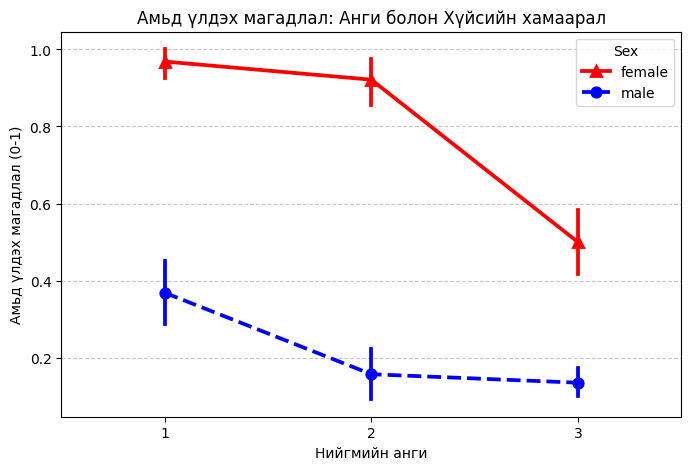

In [11]:
plt.figure(figsize=(8, 5))
sns.pointplot(x='Pclass', y='Survived', hue='Sex', data=df, palette={'male': 'blue', 'female': 'red'}, markers=["^", "o"], linestyles=["-", "--"])

plt.title('Амьд үлдэх магадлал: Анги болон Хүйсийн хамаарал')
plt.ylabel('Амьд үлдэх магадлал (0-1)')
plt.xlabel('Нийгмийн анги')
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.show()

**Хэрхэн унших вэ (Логик):** Та энэ графикаас 3-р ангийн эмэгтэйчүүдийн амьд үлдэх магадлал (~50%) нь 1-р ангийн эрэгтэйчүүдийнхээс (~35%) хамаагүй өндөр байгааг харна. Энэ нь "Нийгмийн анги чухал байсан ч, хүйсийн ялгаа түүнээс ч илүү хүчтэй нөлөөлсөн" гэдгийг батлах хамгийн ухаалаг нотолгоо юм.


### 2. Split Violin Plot: "Нас, хүйсээр хэнийг золиосолсон бэ?"

Насны тархалтыг амьд үлдэх ба нас барсан гэж салгаж харуулахаас гадна эрэгтэй, эмэгтэйгээр нь нэг хэлбэр дотор хувааж харуулдаг маш гоёмсог график.


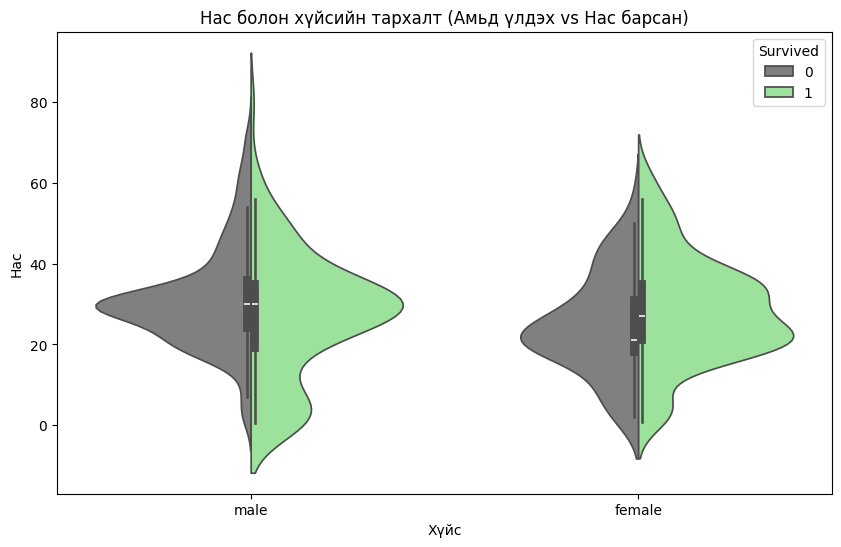

In [12]:
plt.figure(figsize=(10, 6))
sns.violinplot(x="Sex", y="Age", hue="Survived", data=df, split=True, palette={0: "gray", 1: "lightgreen"})

plt.title('Нас болон хүйсийн тархалт (Амьд үлдэх vs Нас барсан)')
plt.ylabel('Нас')
plt.xlabel('Хүйс')
plt.show()

**Хэрхэн унших вэ (Логик):** Эрэгтэй хэсгийн (Male) график руу харахад нас барсан (саарал) хэсэг нь 20-40 насанд маш бүдүүн буюу өргөн болсон байдаг. Энэ нь идэр насны эрчүүд хамгийн ихээр амиа алдсаныг илтгэнэ. Харин 0-10 насны хэсэгт эрэгтэй ч бай, эмэгтэй ч бай амьд үлдэх (ногоон) хэсэг нь илүү өргөн байгааг харах бөгөөд энэ нь "Хүүхдүүдийг эхлээд аварсан" гэдгийн шууд баталгаа болно.


### 3. Boxplot with Hue: "Нэг анги доторх эдийн засгийн ялгаа"

Зөвхөн "Баячууд амьд үлдсэн" гэж хэлэхийн орондоо, "Нэг ангилалд (жишээ нь 1-р анги дотроо) байсан хүмүүсээс арай илүү мөнгө төлсөн нь түрүүлж аврагдсан уу?" гэдгийг шалгана.


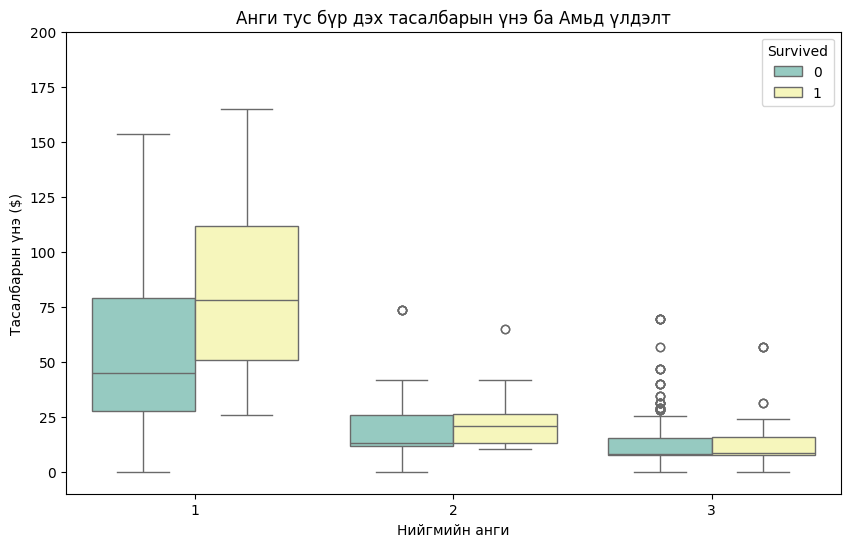

In [13]:
plt.figure(figsize=(10, 6))
sns.boxplot(x="Pclass", y="Fare", hue="Survived", data=df, palette="Set3")

plt.ylim(-10, 200)
plt.title('Анги тус бүр дэх тасалбарын үнэ ба Амьд үлдэлт')
plt.ylabel('Тасалбарын үнэ ($)')
plt.xlabel('Нийгмийн анги')
plt.show()

**Хэрхэн унших вэ (Логик):** 1-р ангийн хайрцгуудыг харахад, амьд үлдсэн хүмүүсийн тасалбарын үнийн дундаж зураас нь нас барагсдынхаас хамаагүй дээр байрлана. Энэ нь баян хүмүүс дотроо хүртэл хамгийн дээд зэргэлэлийн (Premium) үнэтэй өрөө авсан хүмүүс нь эхлээд завинд суух эрхтэй байсан байж болзошгүйг (эсвэл өрөө нь завинтай хамгийн ойр байсныг) нотлох маш нарийн шинжилгээ юм.


## АЛХАМ 10: Машин сургалтын загвар

In [14]:
print("\nАЛХАМ 10: Машин сургалтын загвар")
print("-" * 30)

try:
    df_model = df.copy()
    
    if 'Sex' in df_model.columns:
        df_model['Sex'] = df_model['Sex'].map({'male': 1, 'female': 0})
    
    if 'Embarked' in df_model.columns:
        df_model = pd.get_dummies(df_model, columns=['Embarked'], prefix='Embarked')

    cat_cols = [c for c in ['Title', 'Deck'] if c in df_model.columns]
    if cat_cols:
        df_model = pd.get_dummies(df_model, columns=cat_cols,
                                  prefix=cat_cols)
        print(f"{cat_cols} багануудыг one-hot кодлол хийв")
    
    feature_cols = [col for col in df_model.columns if col not in ['Survived', 'PassengerId', 'AgeGroup', 'FareGroup']]
    
    if 'Survived' in df_model.columns and len(feature_cols) > 0:
        X = df_model[feature_cols]
        y = df_model['Survived']
        
        X = X.fillna(0)
        
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
        
        model = RandomForestClassifier(n_estimators=100, random_state=42)
        model.fit(X_train, y_train)
        
        y_pred = model.predict(X_test)
        
        accuracy = accuracy_score(y_test, y_pred)
        print(f"Загварын нарийвчлал: {accuracy:.1%}")
        
        feature_importance = pd.DataFrame({
            'Хувьсагч': feature_cols,
            'Ач холбогдол': model.feature_importances_
        }).sort_values('Ач холбогдол', ascending=False)
        
        print("\nХувьсагчдын ач холбогдол:")
        for i, row in feature_importance.head().iterrows():
            print(f"   {row['Хувьсагч']}: {row['Ач холбогдол']:.3f}")
    
except Exception as e:
    print(f"Машин сургалтын загварт алдаа: {e}")


АЛХАМ 10: Машин сургалтын загвар
------------------------------
['Title', 'Deck'] багануудыг one-hot кодлол хийв
Загварын нарийвчлал: 81.6%

Хувьсагчдын ач холбогдол:
   Fare: 0.216
   Age: 0.183
   Title_Mr: 0.121
   Sex: 0.108
   Pclass: 0.071


### Дүгнэлт

**Өгөгдлийн шинжилгээ хийнэ гэдэг нь зүгээр л тоо бодох биш юм.** Тоонууд (Dataset) ямар үр дүн зааж байгааг техникийн аргаар олоод, тэр нь бодит амьдрал дээр яагаад тийм байв гэдэг шалтгааныг (Логик) тайлбарлахыг **Жинхэнэ Анализ** гэж нэрлэдэг.


## ЭЦСИЙН ДҮГНЭЛТ

In [15]:
print("\n" + "="*60)
print("ЭЦСИЙН ДҮГНЭЛТ")
print("="*60)

if 'Survived' in df.columns:
    print(f"""
ТИТАНИК ӨГӨГДЛИЙН ШИНЖИЛГЭЭНИЙ ҮР ДҮҮН:

Ерөнхий үзүүлэлт:
   • Нийт зорчигч: {len(df)} хүн
   • Амьд үлдэх хувь: {df['Survived'].mean():.1%}

Гол дүгнэлтүүд:
   • Хүйс хамгийн чухал хүчин зүйл
   • Нийгмийн анги чухал нөлөө үзүүлсэн
   • Эдийн засгийн байдал амьд үлдэхтэй холбоотой
   • "Эмэгтэй, хүүхэд эхлээд" зарчим бодитой

Сургамж:
   • Өгөгдөл цэвэрлэгээ чухал
   • Олон өнцгөөс шинжлэх хэрэгтэй
   • Дүрслэл ойлголтод тусалдаг
   • Статистик болон машин сургалт хослуулах нь үр дүнтэй
    """)

print("\nШинжилгээ дуусгавар болов!")
print("Дараагийн алхам: Илүү нарийвчилсан загвар бүтээх, cross-validation хийх")


ЭЦСИЙН ДҮГНЭЛТ

ТИТАНИК ӨГӨГДЛИЙН ШИНЖИЛГЭЭНИЙ ҮР ДҮҮН:

Ерөнхий үзүүлэлт:
   • Нийт зорчигч: 891 хүн
   • Амьд үлдэх хувь: 38.4%

Гол дүгнэлтүүд:
   • Хүйс хамгийн чухал хүчин зүйл
   • Нийгмийн анги чухал нөлөө үзүүлсэн
   • Эдийн засгийн байдал амьд үлдэхтэй холбоотой
   • "Эмэгтэй, хүүхэд эхлээд" зарчим бодитой

Сургамж:
   • Өгөгдөл цэвэрлэгээ чухал
   • Олон өнцгөөс шинжлэх хэрэгтэй
   • Дүрслэл ойлголтод тусалдаг
   • Статистик болон машин сургалт хослуулах нь үр дүнтэй
    

Шинжилгээ дуусгавар болов!
Дараагийн алхам: Илүү нарийвчилсан загвар бүтээх, cross-validation хийх
